Comprobar si se esta usando la GPU

In [ ]:
!nvidia-smi # Muestra la información de la GPU si se esta utilizando

Mon Nov 17 16:53:41 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Preparar dataset y modelo

In [ ]:
!pip install ultralytics # Se instala el paquete ultralytics en el entorno
import ultralytics # Se importa el paquete, es el que contiene el modelo YOLO
ultralytics.checks() # Hace un diagnostico del entorno, muestra la version instalada, la version de python, el cuda utilizado, etc.

Ultralytics 8.3.228 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 38.5/112.6 GB disk)


In [ ]:
# Se instala el paquete roboflow en el entorno
# Roboflow fue la plataforma en la que subimos el dataset y realizamos las anotaciones
# Desde roboflow definimos la distribución de las imagenes
# La distribución definida fue 70% train, 20% val, 10% test
!pip install roboflow

from roboflow import Roboflow # Se importa roboflow
# Información del dataset necesaria para su importación
# Esto descarga el dataset en el entorno
# Esto se genera dentro de la plataforma de roboflow, ya que el Api Key es diferente para cada dataset
rf = Roboflow(api_key="hNOxo38TI1TPq8hnHuon")
project = rf.workspace("uprojects").project("yolov8-leaf-segmentation-dcccn")
version = project.version(6)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...


**Preprocesamiento**

En roboflow, al dataset le habiamos aplicado:

*   Resize de 640x60
*   Auto-orient


Pero además, realizamos data augmentation con:
poner data augmentation





Aqui, adicionalmente realizamos un preprocesamiento de las imágenes después de importar el dataset.

Lo que realizamos fue un cambio de espacio de color de BGR a LAB, para poder aplicar una ecualización de histograma al brillo.

In [ ]:
import cv2
import glob # Libreria para buscar archivos que coincidan
import os
import numpy as np

# Definimos la ruta
# Carpeta original de imágenes
src_folder = os.path.join(dataset.location, "train/images")

# CLAHE para mejorar contraste
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)) # Creamos el objeto clahe con cv2
# La idea es utilizar esta ecualización de histograma para mejorar el contraste entre el brillo

# Buscar imágenes con diferentes extensiones
extensions = ["*.jpg", "*.JPG", "*.jpeg", "*.JPEG", "*.png", "*.PNG"]

image_paths = [] # Arreglo del path de las imágenes
for ext in extensions:
    image_paths.extend(glob.glob(os.path.join(src_folder, ext))) # Con glob, recorremos toda la carpeta y buscamos coincidencias

print(f"Total de imágenes encontradas: {len(image_paths)}") # Imprimimos el total de imágenes encontradas para validar

for img_path in image_paths:
    img = cv2.imread(img_path) # Recorremos todas las imágenes y las leemos con cv2

    if img is None:
        print(f"No se pudo leer: {img_path}") # Para validar si alguna imagen no se pudo procesar
        continue

    # Convertir a LAB
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab) # Partimos los canales

    # Aplicar CLAHE al canal L
    l = clahe.apply(l)

    # Reconstruir imagen
    lab = cv2.merge((l, a, b))
    img_clahe = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR) # Convertir a BGR

    # Sobrescribir la imagen original
    cv2.imwrite(img_path, img_clahe) # Para no cambiar el archivo data.yaml

print("Todas las imágenes fueron PREPROCESADAS y REEMPLAZADAS correctamente.")


Total de imágenes encontradas: 732
Todas las imágenes fueron PREPROCESADAS y REEMPLAZADAS correctamente.


Entrenamiento

In [ ]:
# Ejecutamos el comando yolo para el modelo
# Definimos la tarea, la cual es segmentación
# Definimos el estado del modelo, que en este caso sería entrenamiento
# Indicamos donde encuentra el dataset, apuntando al data.yaml
# Definimos un número de epocas, en este caso 50
# Definimos el tamaño de imágen que recibe el modelo, en este caso 640x640
!yolo task=segment mode=train model=yolov8l-seg.pt data={dataset.location}/data.yaml epochs=50 imgsz=640

Ultralytics 8.3.228 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Yolov8-Leaf-Segmentation-6/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8l-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.

In [ ]:
from IPython import display
display.clear_output()

from ultralytics import YOLO

from IPython.display import display, Image

Matriz de confusión

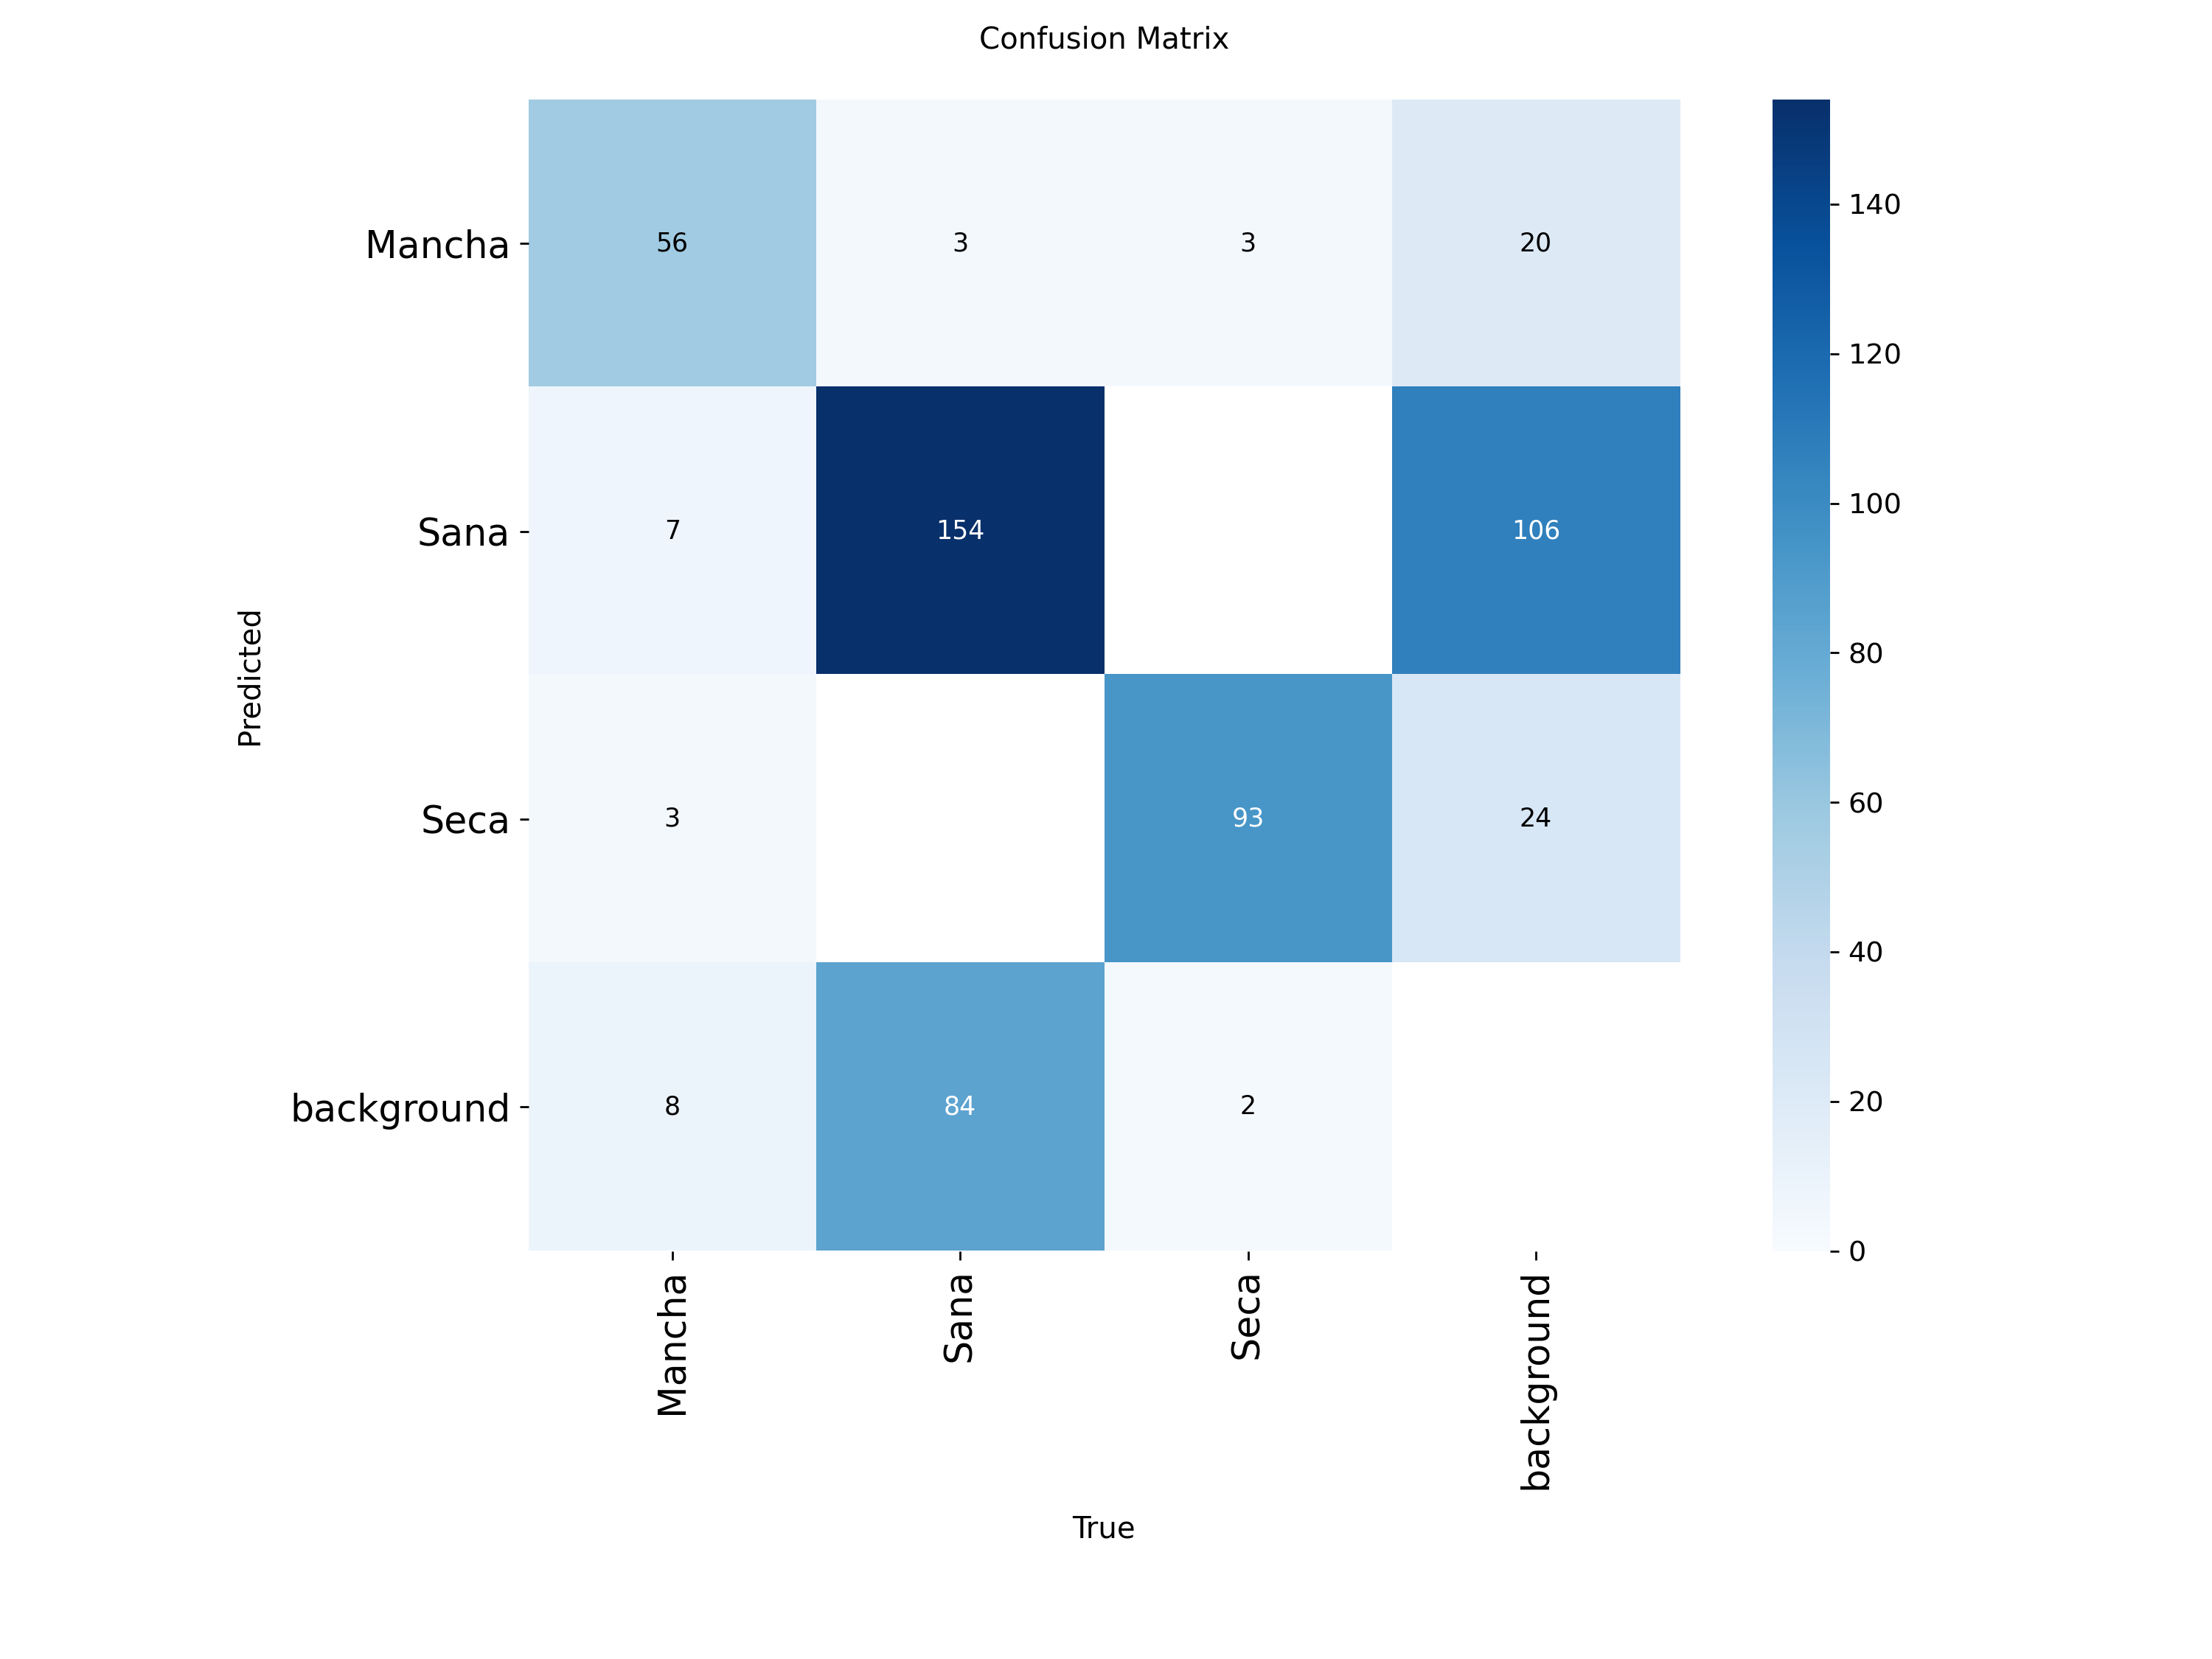

In [ ]:
Image(filename='/content/runs/segment/train/confusion_matrix.png', width=600)

Predecir una imagen que no esta en el dataset

In [ ]:
model = YOLO("runs/segment/train/weights/best.pt") # Se llama al modelo, en este caso, el que tuvo el mejor resultado en el entrenamiento

In [ ]:
# Ponemos el modelo en modo predict
# Con source ponemos la ruta de la imagen de la que se quiere predecir
# Con conf, definimos el umbral aceptado, en este caso solo acepta detecciones con más de 50% de confianza
# Show abre una ventana para mostrar los resultados, por eso lo pusimos en False, ya que Colab no tiene soporte para esa función
# save en True para guardar el resultado del predict
results = model.predict(source="Prueba.png", conf=0.5, show=False, save=True)


image 1/1 /content/Prueba.png: 640x640 4 Manchas, 1 Sana, 4 Secas, 76.1ms
Speed: 2.9ms preprocess, 76.1ms inference, 24.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/segment/predict


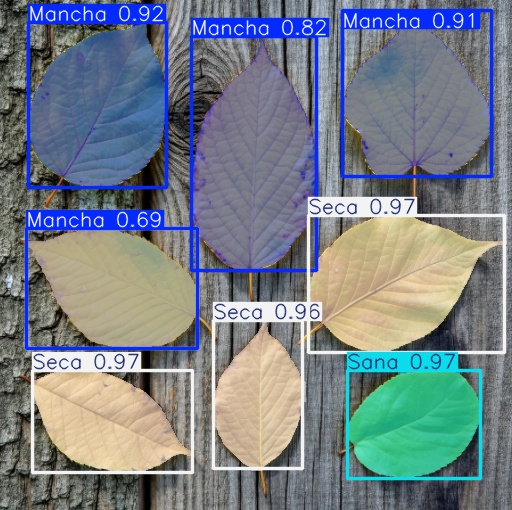

In [ ]:
# Cargamos la imagen que predijo el modelo
Image(filename='/content/runs/segment/predict/Prueba.jpg', width=600)

In [ ]:
# Ponemos el modelo en modo validacion, y cargamos el best del entrenamiento, para poder observar las metricas del modelo a implementar
!yolo task=segment mode=val model=/content/runs/segment/train/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.3.228 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8l-seg summary (fused): 125 layers, 45,914,201 parameters, 0 gradients, 210.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2680.4±507.6 MB/s, size: 113.7 KB)
val: Scanning /content/Yolov8-Leaf-Segmentation-6/valid/labels.cache... 71 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 71/71 1.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.2s/it 6.2s
                   all         71        413      0.782      0.741      0.804      0.687      0.821      0.711      0.801      0.686
                Mancha         21         74      0.834      0.749      0.833      0.735      0.865      0.716       0.82        0.7
                  Sana         35        241      0.659      0.546      0.616      0.502      0.716      0.498      0.622      0.481
                  Seca     

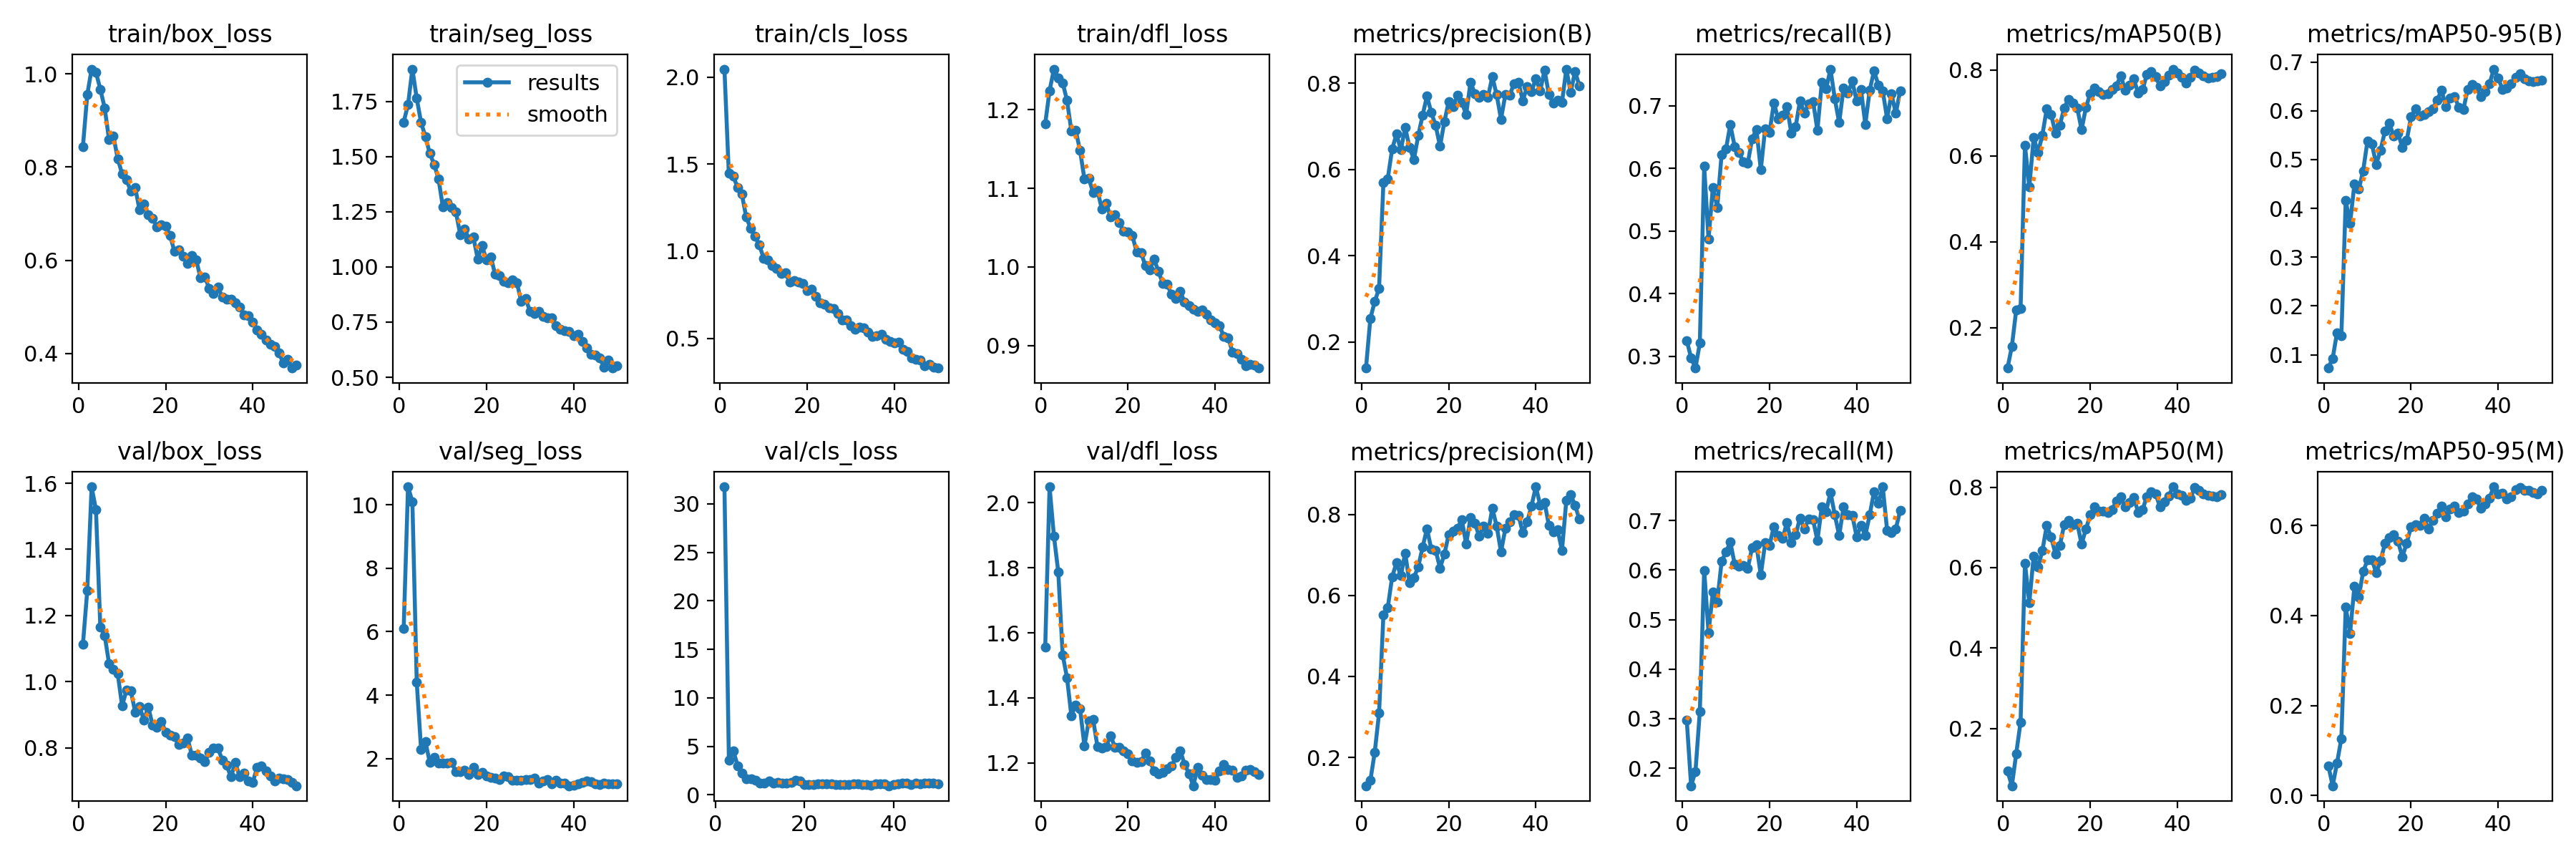

In [ ]:
# Cargamos los resultados del entrenamiento del modelo
Image(filename=f'/content/runs/segment/train/results.png', width=1200)

In [ ]:
# Importamos la libreria pandas
import pandas as pd

In [ ]:
model_result = pd.read_csv("/content/runs/segment/train/results.csv") # El modelo tambien genera un .csv, asi que lo cargamos

In [ ]:
model_result # Mostramos el resultado de cada epoca

,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),...,metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,50.4732,0.84346,1.65633,2.04593,1.18224,0.13970,0.32502,0.10565,0.07271,...,0.29711,0.09355,0.06629,1.11237,6.09139,inf,1.55580,0.000466,0.000466,0.000466
1,2,107.0790,0.95545,1.73556,1.44870,1.22437,0.25432,0.29734,0.15642,0.09221,...,0.16455,0.05753,0.02146,1.27537,10.56960,31.76090,2.04854,0.000924,0.000924,0.000924
2,3,161.3560,1.01020,1.89644,1.43313,1.25182,0.29380,0.28102,0.24113,0.14522,...,0.19337,0.13794,0.07172,1.58913,10.10340,3.56721,1.89728,0.001362,0.001362,0.001362
3,4,215.9900,1.00317,1.76385,1.36620,1.24070,0.32386,0.32076,0.24408,0.13878,...,0.31427,0.21611,0.12658,1.51927,4.40437,4.51267,1.78687,0.001344,0.001344,0.001344
4,5,271.8170,0.96712,1.65376,1.32684,1.23454,0.56937,0.60331,0.62459,0.41583,...,0.59974,0.61132,0.41870,1.16462,2.28310,2.98683,1.53280,0.001316,0.001316,0.001316
5,6,328.9790,0.92694,1.59024,1.19604,1.21217,0.57875,0.48692,0.52758,0.36903,...,0.47392,0.51269,0.36036,1.14013,2.52623,2.26447,1.46256,0.001288,0.001288,0.001288
6,7,386.3250,0.85904,1.51410,1.13282,1.17340,0.64694,0.56984,0.64207,0.45017,...,0.55530,0.62872,0.46537,1.05523,1.87347,1.65164,1.34551,0.001259,0.001259,0.001259
7,8,465.7800,0.86643,1.46416,1.08511,1.17385,0.68203,0.53753,0.60743,0.43895,...,0.53576,0.60114,0.44074,1.03729,2.03806,1.65048,1.37778,0.001231,0.001231,0.001231
8,9,519.4980,0.81778,1.39923,1.03608,1.14839,0.64526,0.62240,0.64857,0.47674,...,0.61738,0.64206,0.49779,1.02370,1.84833,1.49674,1.36740,0.001203,0.001203,0.001203
9,10,588.8940,0.78535,1.27145,0.96032,1.11189,0.69690,0.63066,0.70926,0.53852,...,0.63656,0.70426,0.52330,0.92717,1.85699,1.22145,1.25230,0.001174,0.001174,0.001174


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

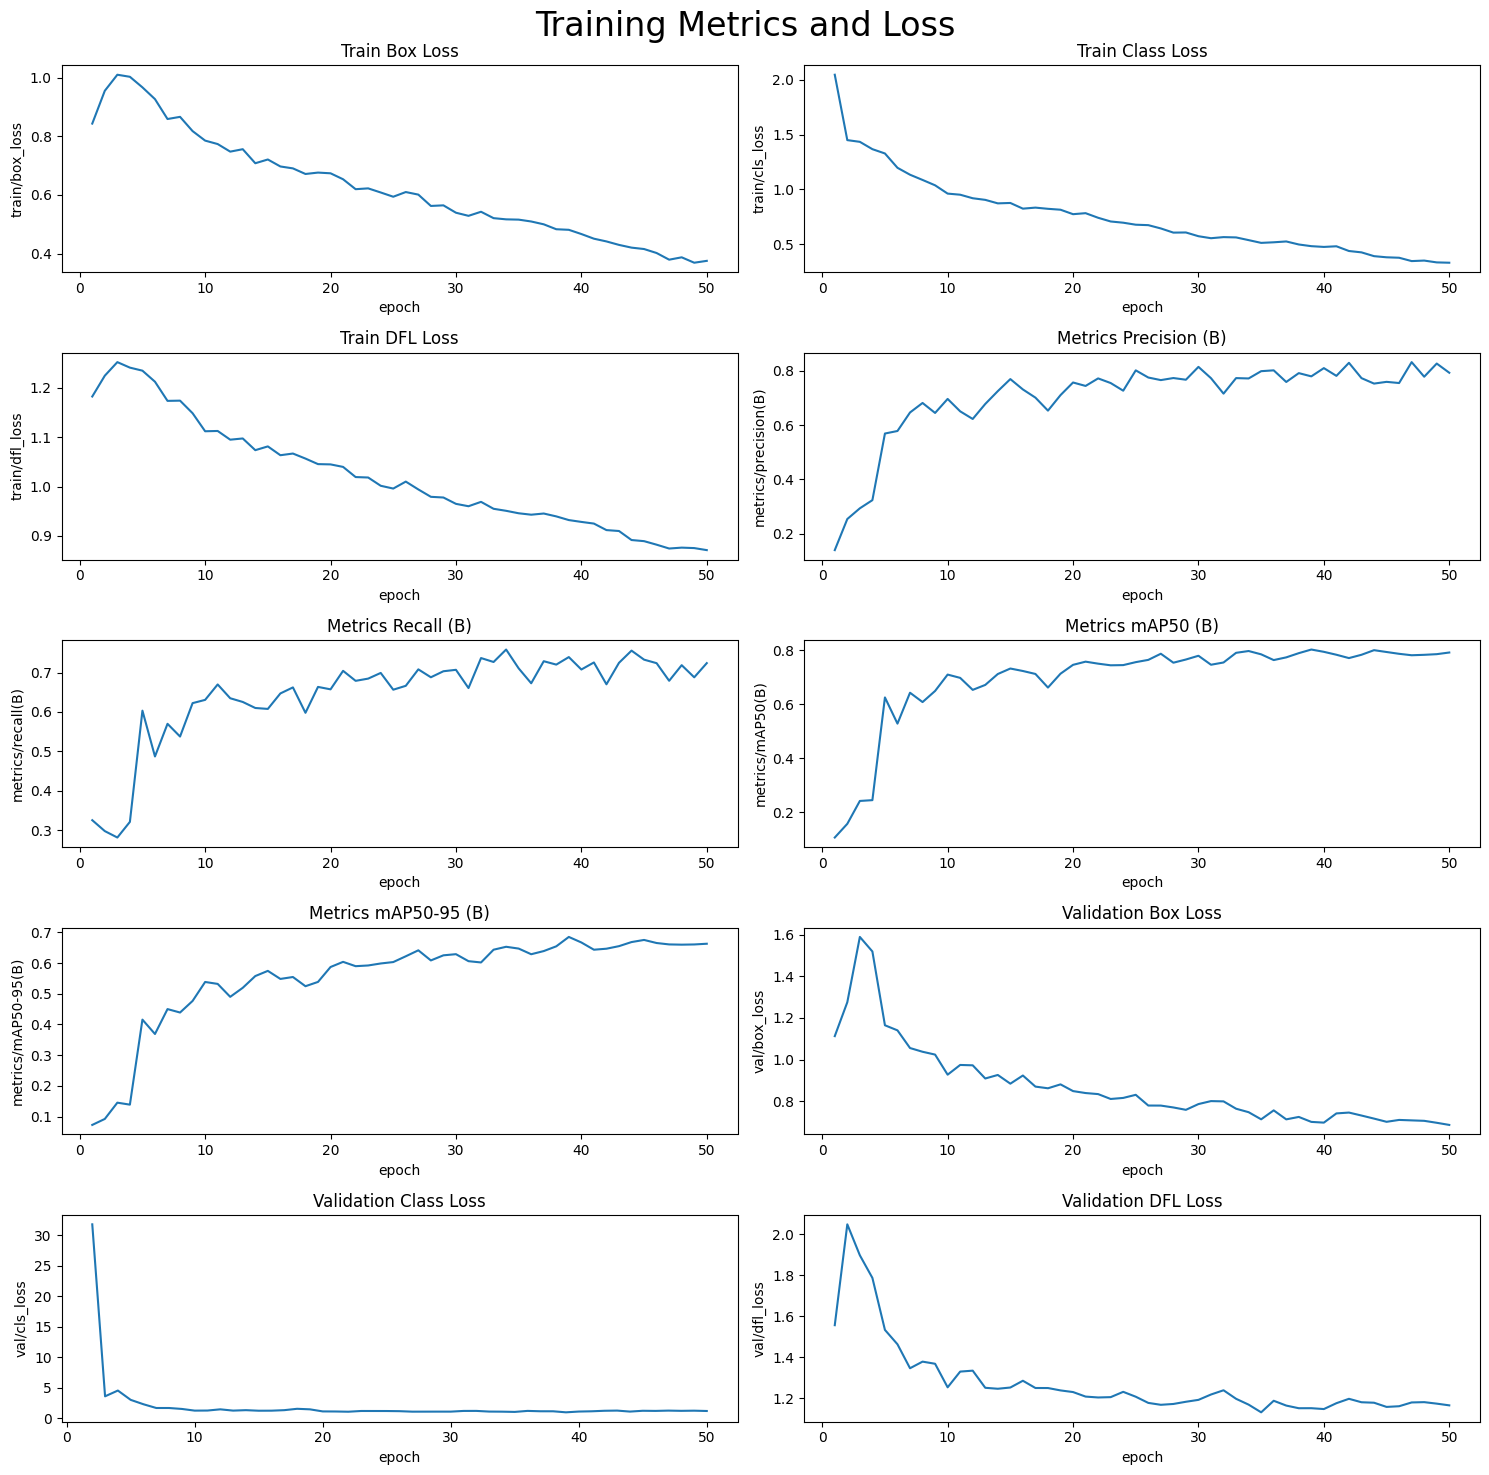

In [ ]:
model_result.columns = model_result.columns.str.strip()

fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(15, 15))

sns.lineplot(x='epoch', y='train/box_loss', data=model_result, ax=axs[0,0])
sns.lineplot(x='epoch', y='train/cls_loss', data=model_result, ax=axs[0,1])
sns.lineplot(x='epoch', y='train/dfl_loss', data=model_result, ax=axs[1,0])
sns.lineplot(x='epoch', y='metrics/precision(B)', data=model_result, ax=axs[1,1])
sns.lineplot(x='epoch', y='metrics/recall(B)', data=model_result, ax=axs[2,0])
sns.lineplot(x='epoch', y='metrics/mAP50(B)', data=model_result, ax=axs[2,1])
sns.lineplot(x='epoch', y='metrics/mAP50-95(B)', data=model_result, ax=axs[3,0])
sns.lineplot(x='epoch', y='val/box_loss', data=model_result, ax=axs[3,1])
sns.lineplot(x='epoch', y='val/cls_loss', data=model_result, ax=axs[4,0])
sns.lineplot(x='epoch', y='val/dfl_loss', data=model_result, ax=axs[4,1])

axs[0,0].set(title='Train Box Loss')
axs[0,1].set(title='Train Class Loss')
axs[1,0].set(title='Train DFL Loss')
axs[1,1].set(title='Metrics Precision (B)')
axs[2,0].set(title='Metrics Recall (B)')
axs[2,1].set(title='Metrics mAP50 (B)')
axs[3,0].set(title='Metrics mAP50-95 (B)')
axs[3,1].set(title='Validation Box Loss')
axs[4,0].set(title='Validation Class Loss')
axs[4,1].set(title='Validation DFL Loss')

plt.suptitle('Training Metrics and Loss', fontsize=24)
plt.subplots_adjust(top=0.8)
plt.tight_layout()
plt.show()